In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
import os

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def calc_ccc(x, y):
    x = np.asarray(x)
    y = np.asarray(y)

    mx = np.mean(x)
    my = np.mean(y)
    vx = np.var(x, ddof=0)
    vy = np.var(y, ddof=0)
    sxy = np.cov(x, y, ddof=0)[0, 1]

    return 2 * sxy / (vx + vy + (mx - my) ** 2)

def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def load_pf_data(protein, model_name, ensemble_dir="MD_DATA", exp_dir="EXP_DATA/PF_Nguyen_2018"):
    exp = pd.read_csv(f"../../{exp_dir}/{protein}.csv")
    residues = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/exp_residues.txt")
    priorPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/prior_lnPF.txt"))

    # stats is currently unused, so this read is commented out.
    # stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/stats_df.csv")
    stats = None

    if model_name in ("rewBV2006", "rewBV2006ang"):
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/reweighting_chi2_phi_theta.txt")
        chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/rew_lnPF.txt"))
    else:
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_reweighting_chi2_phi_theta.txt")
        chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_rew_lnPF.txt"))

    idxs = [list(exp["Model_residue"]).index(ele) for ele in residues]

    return exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs


# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

def compute_free_energy(protein, model_name, native_contacts_dir, ensemble_dir="MD_DATA", nbins=30, unfolded_cutoff=0.1, wopt=None):
    k = 0.008314
    T = 298.0
    kT = k * T

    ntrajs = len(find_xtc_filenames(f"../../{ensemble_dir}/{protein}/"))
    # get correct traj order
    trajs = np.array(sorted(list(np.arange(ntrajs).astype(str)))).astype(int)

    # Load Q data
    for i in trajs:
        if 'M' in model_name:
            frames = np.loadtxt(f"../../{ensemble_dir}/{protein}/rewM10/okframes_traj{i}.txt").astype(int)
            Q = np.loadtxt(f"../../{ensemble_dir}/{protein}/{native_contacts_dir}/Q{i}.txt")[frames]
            if i == 0:
                Q_all = Q
            else:
                Q_all = np.concatenate((Q_all, Q))
        else: # for models where no filtering was needed
            Q = np.loadtxt(f"../../{ensemble_dir}/{protein}/{native_contacts_dir}/Q{i}.txt")
            if i == 0:
                Q_all = Q
            else:
                Q_all = np.concatenate((Q_all, Q))
    if wopt is None:
        try:
            wopt = np.load(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_wopt.npy")
        except:
            wopt = np.load(f"../../{ensemble_dir}/{protein}/{model_name}/wopt.npy")
        wopt = wopt / np.sum(wopt)

    # Histograms
    def compute_FEL(Q, weights=None):
        counts, bins = np.histogram(Q, bins=nbins, weights=weights)
        centers = 0.5 * (bins[1:] + bins[:-1])
        p = counts / np.sum(counts)
        p[p <= 0] = np.nan
        fel = -np.log(p) * kT
        fel -= np.nanmin(fel)
        return centers, fel * 0.239005736

    centers_prior, fel_prior = compute_FEL(Q_all)
    centers_post, fel_post = compute_FEL(Q_all, weights=wopt)

    # Energetics 1: completely unfolded state relative to native state (comparable to what HDX probes)
    unfolded = np.where(Q_all < unfolded_cutoff)[0]
    # get cutoff for folded state from FEL
    min_Q_idx = np.where(fel_prior ==np.min(fel_prior))[0]
    minQ = centers_prior[min_Q_idx]
    native_cutoff = 0.7 * minQ
    folded = np.where(Q_all > native_cutoff)[0]

    dG_prior = -kT * np.log(len(folded) / len(unfolded)) * 0.239005736
    dG_post = -kT * np.log(np.sum(wopt[folded]) / np.sum(wopt[unfolded])) * 0.239005736

    # Energetics 2: native state relative to the rest (including potential intermediates, comparable to what cDNA proteolysis probes)
    # criteria: the main energy barrier between native and unfolded must be overcome --> cutoff decided as the max free energy between Q 0.2 and 0.8
    mask = (centers_prior > 0.2) & (centers_prior < 0.8)
    max_Q_idx = np.where(fel_prior ==np.max(fel_prior[mask]))[0][0]
    native_cutoff2 = centers_prior[max_Q_idx]
    folded = np.where(Q_all > native_cutoff2)[0]
    unfolded = np.where(Q_all < native_cutoff2)[0]

    dG_prior2 = -kT * np.log(len(folded) / len(unfolded)) * 0.239005736
    dG_post2 = -kT * np.log(np.sum(wopt[folded]) / np.sum(wopt[unfolded])) * 0.239005736

    return centers_prior, fel_prior, centers_post, fel_post, dG_prior, dG_post, dG_prior2, dG_post2, native_cutoff, native_cutoff2

outpath = './other_plots/'


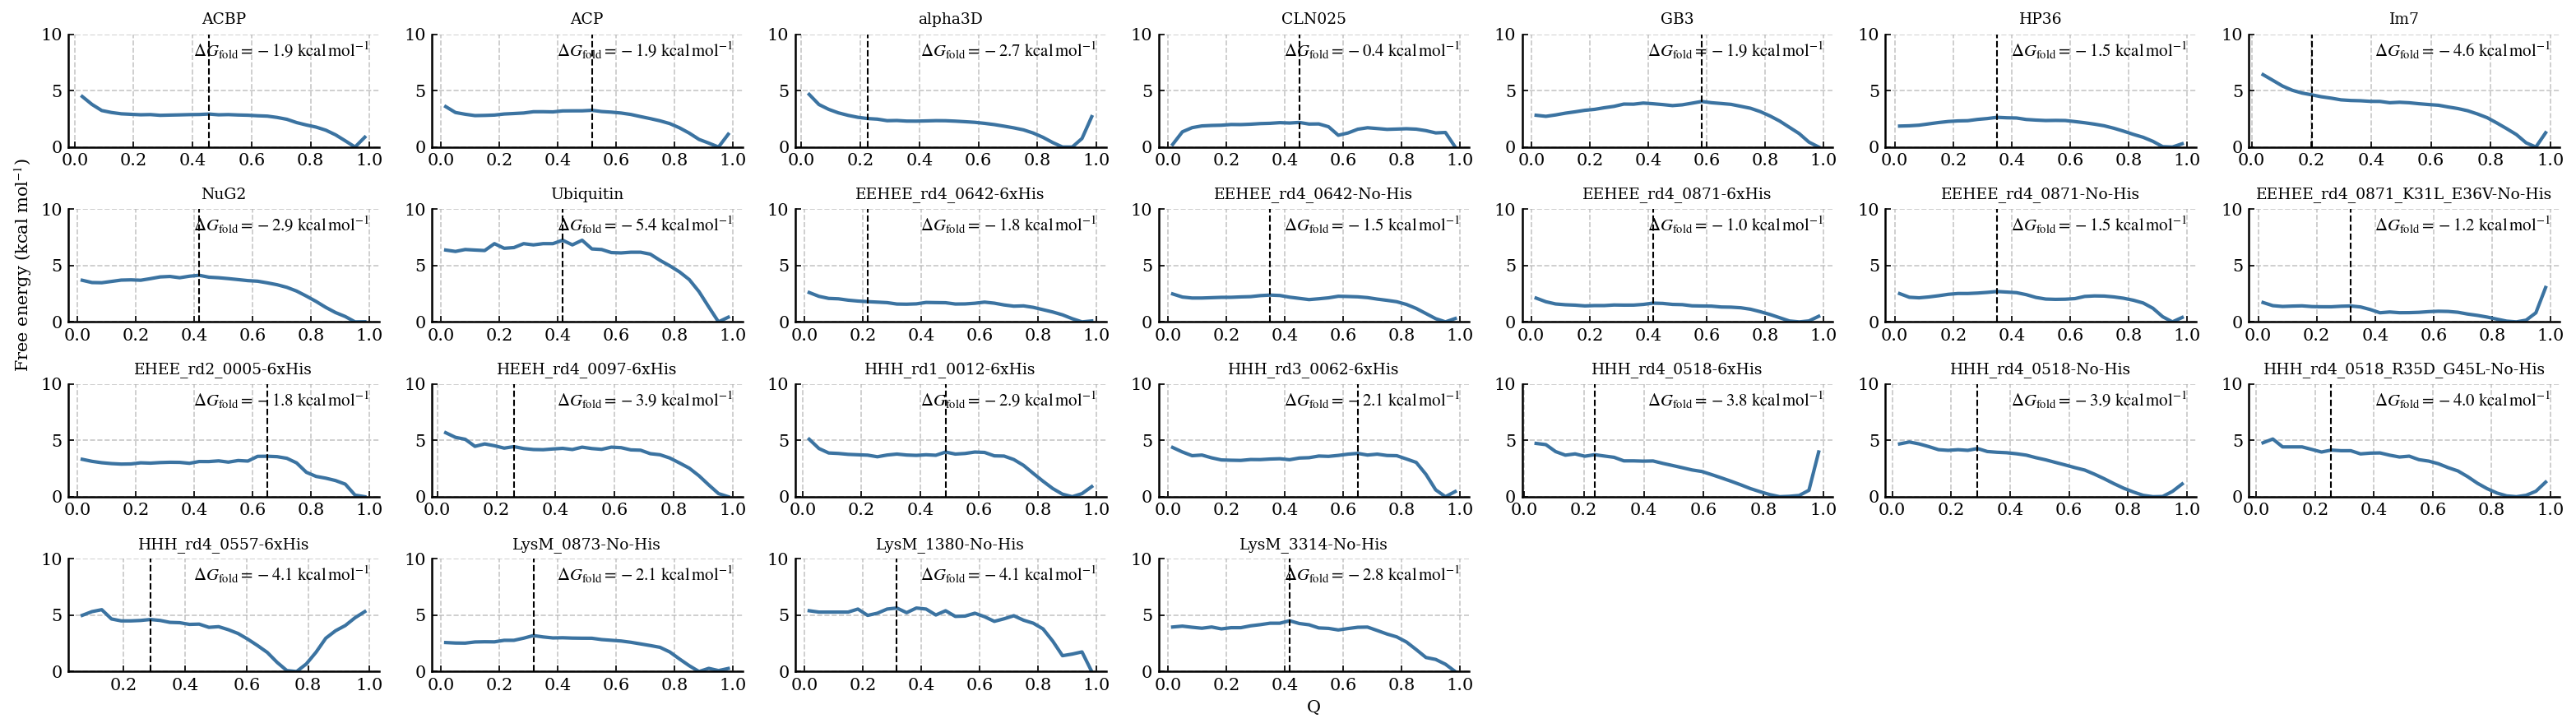

In [9]:
proteins = ['ACBP', 'ACP', 'alpha3D', 'CLN025', 'GB3', 'HP36', 'Im7', 'NuG2', 'Ubiquitin',
            'EEHEE_rd4_0642-6xHis', 'EEHEE_rd4_0642-No-His',
            'EEHEE_rd4_0871-6xHis', 'EEHEE_rd4_0871-No-His',
            'EEHEE_rd4_0871_K31L_E36V-No-His', 'EHEE_rd2_0005-6xHis',
            'HEEH_rd4_0097-6xHis', 'HHH_rd1_0012-6xHis', 'HHH_rd3_0062-6xHis',
            'HHH_rd4_0518-6xHis', 'HHH_rd4_0518-No-His',
            'HHH_rd4_0518_R35D_G45L-No-His', 'HHH_rd4_0557-6xHis',
            'LysM_0873-No-His', 'LysM_1380-No-His', 'LysM_3314-No-His']

model_name = 'rewM10'
unfolded_cutoff = 0.1
native_contacts_dir = 'native_contacts'
COLOR = "#3B73A1"

ncols = 7
nrows = int(np.ceil(len(proteins) / ncols))  # 4 rows for 25 proteins; set nrows=3 manually if you trim the list

fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 1.5 * nrows))
axes = axes.flatten()

for i, protein in enumerate(proteins):
    ax = axes[i]
    try:
        (centers_prior, fel_prior, centers_post, fel_post,
         dG_prior, dG_post, dG_prior2, dG_post2,
         native_cutoff, native_cutoff2) = compute_free_energy(
            protein, model_name=model_name, ensemble_dir='BIOEMU_DATA',
            native_contacts_dir=native_contacts_dir, unfolded_cutoff=unfolded_cutoff
        )
    except Exception as e:
        ax.set_title(f"{protein}\n(failed: {e})", fontsize=8)
        ax.axis("off")
        continue

    ax.plot(centers_prior, fel_prior, color=COLOR, linewidth=2, label='Prior (BioEmu)')
    ax.axvline(native_cutoff2, color="k", linestyle="--", linewidth=1)

    ax.text(0.97, 0.95,
            rf"$\Delta G_{{\mathrm{{fold}}}} = {dG_prior2:.1f}\ \mathrm{{kcal\,mol^{{-1}}}}$",
            transform=ax.transAxes, ha="right", va="top", fontsize=10)

    if protein==proteins[-1]:  # Add legend only to the last subplot
        ax.set_xlabel("Q")
    if protein=='NuG2':
        ax.set_ylabel("Free energy (kcal mol$^{-1}$)")
    ax.set_title(protein, fontsize=9)
    ax.set_ylim(0, 10)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", which="both", top=False, right=False)

# turn off any unused axes (e.g. last 3 slots when 25 proteins fill a 4x7 grid)
for j in range(len(proteins), len(axes)):
    axes[j].axis("off")

# single shared legend instead of one per subplot
#handles, labels = axes[0].get_legend_handles_labels()
#fig.legend(handles, labels, loc='upper center', ncol=1, bbox_to_anchor=(0.5, 1.02))

plt.tight_layout()
plt.savefig(outpath + "all_proteins_prior_FEL.pdf", dpi=300, bbox_inches="tight")
plt.show()